<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes
Example 1 (Yes):  S = ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
                    G = [['?', '?', '?', '?', '?', '?']]
Example 2 (Yes):  S = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
                    G = [['?', '?', '?', '?', '?', '?']]
Example 3 (No):  S = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
                    G = [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]
Example 4 (Yes):  S = ['Sunny', 'Warm', '?', 'Strong', '?', '?']
                    G = [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]

Final specific boundary S: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
Final 

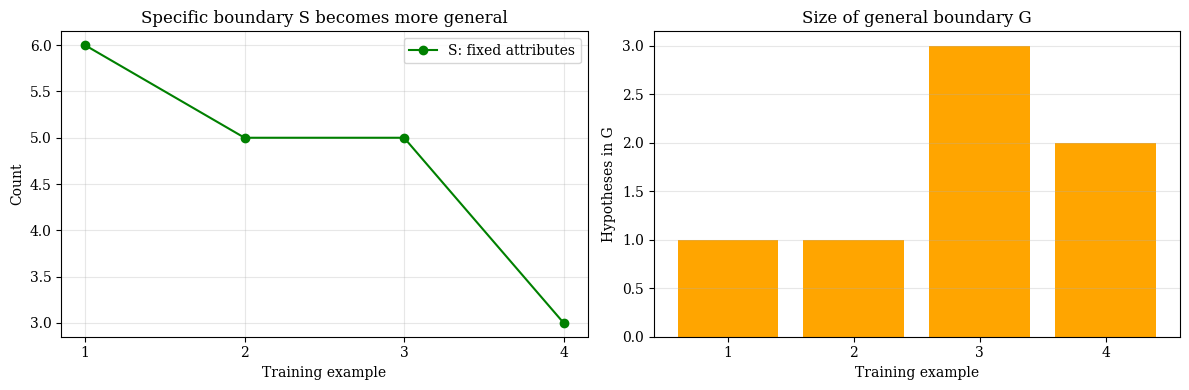

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["font.family"] = "serif"

# Training data stored in a CSV file (used by Program 1 and 2)
csv_text = """Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
Sunny,Warm,Normal,Strong,Warm,Same,Yes
Sunny,Warm,High,Strong,Warm,Same,Yes
Rainy,Cold,High,Strong,Warm,Change,No
Sunny,Warm,High,Strong,Cool,Change,Yes
"""
with open("enjoysport.csv", "w") as f:
    f.write(csv_text)
print(pd.read_csv("enjoysport.csv"))

df = pd.read_csv("enjoysport.csv")
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
n = X.shape[1]
domains = [sorted(set(X[:, j])) for j in range(n)]

def covers(h, x):
    return all(h[k] == "?" or h[k] == x[k] for k in range(len(h)))

def more_general_or_equal(g, h):
    return all(g[k] == "?" or g[k] == h[k] for k in range(len(g)))

S = list(X[0])                    # first example is positive
G = [["?"] * n]
S_hist, G_hist = [], []

for i, (x, label) in enumerate(zip(X, y), 1):
    if label == "Yes":
        for j in range(n):
            if S[j] != x[j]:
                S[j] = "?"
        G = [g for g in G if covers(g, x)]
    else:
        newG = []
        for g in G:
            if not covers(g, x):
                newG.append(g)
                continue
            for j in range(n):    # minimal specializations
                if g[j] == "?":
                    for v in domains[j]:
                        if v != x[j]:
                            h = g.copy(); h[j] = v
                            if more_general_or_equal(h, S):
                                newG.append(h)
        # keep only maximally general hypotheses (no duplicates)
        G = []
        for h in newG:
            if h not in G and not any(g != h and more_general_or_equal(g, h) for g in newG):
                G.append(h)
    S_hist.append(sum(v != "?" for v in S))
    G_hist.append(len(G))
    print(f"Example {i} ({label}):  S = {S}")
    print(f"                    G = {G}")

print("\nFinal specific boundary S:", S)
print("Final general boundary G :", G)

# ---- Graph
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
steps = range(1, len(y) + 1)
ax[0].plot(steps, S_hist, "o-", label="S: fixed attributes", color="green")
ax[0].set_xlabel("Training example"); ax[0].set_ylabel("Count")
ax[0].set_title("Specific boundary S becomes more general")
ax[0].set_xticks(list(steps)); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].bar(steps, G_hist, color="orange")
ax[1].set_xlabel("Training example"); ax[1].set_ylabel("Hypotheses in G")
ax[1].set_title("Size of general boundary G")
ax[1].set_xticks(list(steps)); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()